### Model Achitecture basic:

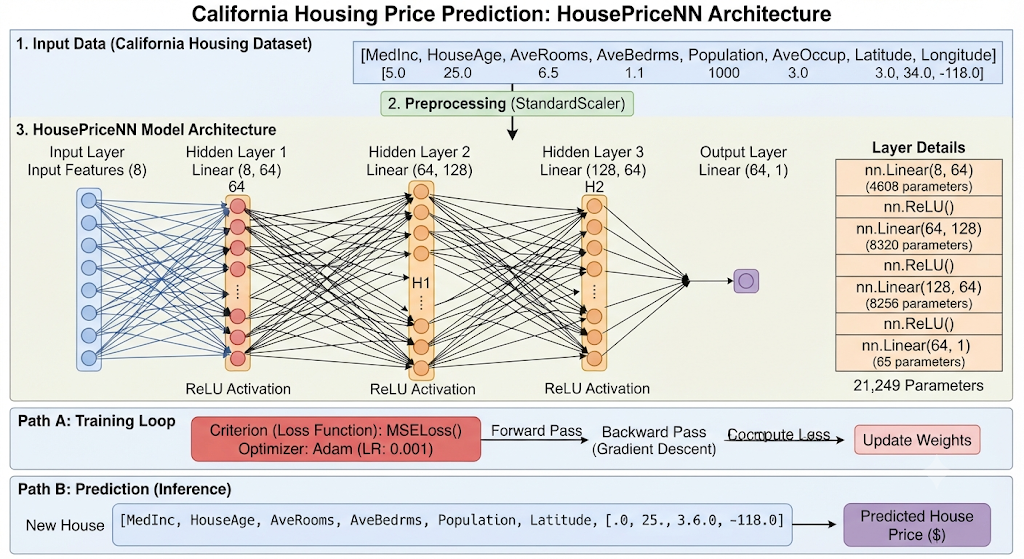

### Model Architecture:

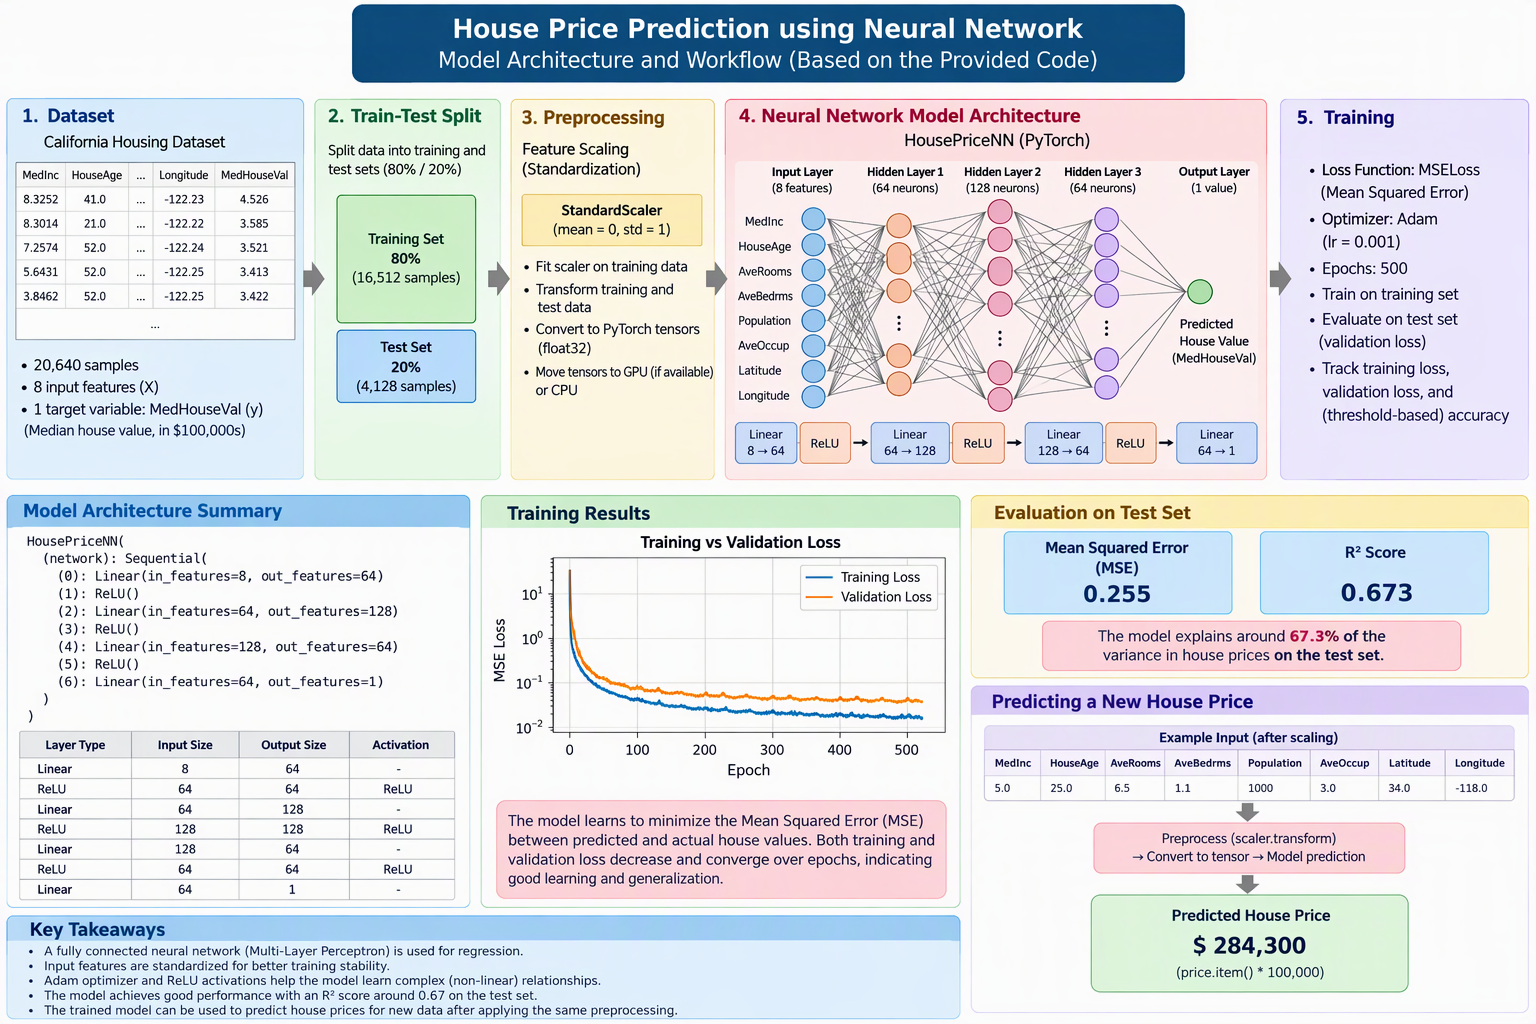

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:

housing = fetch_california_housing(as_frame=True)
df = housing.frame
print(df.head())
print(df.shape)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  
(20640, 9)


In [3]:
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
print(df.columns)

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='str')


In [5]:
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
).reshape(-1,1)

y_test_tensor = torch.tensor(
    y_test.values,
    dtype=torch.float32
).reshape(-1,1)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)

## Create DataLoaders for Mini-batch Training
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

X_train_tensor shape: torch.Size([16512, 8])
y_train_tensor shape: torch.Size([16512, 1])
X_test_tensor shape: torch.Size([4128, 8])
y_test_tensor shape: torch.Size([4128, 1])


In [9]:
X_train_tensor = X_train_tensor.to(device)
y_train_tensor = y_train_tensor.to(device)

X_test_tensor = X_test_tensor.to(device)
y_test_tensor = y_test_tensor.to(device)

In [10]:
import torch.nn as nn
class HousePriceNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(8, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

#model = HousePriceNN()
model = HousePriceNN().to(device)


print(model)

HousePriceNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [11]:
import torch.nn as nn
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

###  Training the model

In [12]:
loss_history = []
accuracy_history = []
epochs = 500
val_loss_history = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    predictions = model(X_train_tensor)    
    
    loss = criterion(predictions, y_train_tensor)
    
    loss.backward()
    
    optimizer.step()
    
    model.eval()
    
    with torch.no_grad():
        val_pred = model(X_test_tensor)
        val_loss = criterion(val_pred, y_test_tensor)
        predicted_classes = (predictions >= 0.5).float()
        accuracy = (
            (predicted_classes == y_train_tensor)
            .float()
            .mean()
            .item()
            * 100
        )   

    loss_history.append(loss.item())
    accuracy_history.append(accuracy)
    val_loss_history.append(val_loss.item())

    rmse_loss = torch.sqrt(loss)

    if epoch % 25 == 0:
        print(
            f"Epoch [{epoch}/{epochs}] "
            f"Loss(MSE)={loss.item():.4f} "
            f"Loss(RMSE)={rmse_loss.item():.4f}"
            f"Accuracy={accuracy:.2f}%"
            f"Validation Loss={val_loss.item():.4f}"    
        )

Epoch [0/500] Loss(MSE)=5.3480 Loss(RMSE)=2.3126Accuracy=0.00%Validation Loss=5.0698
Epoch [25/500] Loss(MSE)=1.3571 Loss(RMSE)=1.1649Accuracy=0.32%Validation Loss=1.3318
Epoch [50/500] Loss(MSE)=0.6892 Loss(RMSE)=0.8302Accuracy=0.32%Validation Loss=0.7062
Epoch [75/500] Loss(MSE)=0.5674 Loss(RMSE)=0.7533Accuracy=0.32%Validation Loss=0.5785
Epoch [100/500] Loss(MSE)=0.4767 Loss(RMSE)=0.6905Accuracy=0.32%Validation Loss=0.4924
Epoch [125/500] Loss(MSE)=0.4331 Loss(RMSE)=0.6581Accuracy=0.32%Validation Loss=0.4467
Epoch [150/500] Loss(MSE)=0.4050 Loss(RMSE)=0.6364Accuracy=0.32%Validation Loss=0.4160
Epoch [175/500] Loss(MSE)=0.3843 Loss(RMSE)=0.6199Accuracy=0.32%Validation Loss=0.3943
Epoch [200/500] Loss(MSE)=0.3677 Loss(RMSE)=0.6064Accuracy=0.32%Validation Loss=0.3784
Epoch [225/500] Loss(MSE)=0.3517 Loss(RMSE)=0.5930Accuracy=0.32%Validation Loss=0.3636
Epoch [250/500] Loss(MSE)=0.3363 Loss(RMSE)=0.5799Accuracy=0.32%Validation Loss=0.3498
Epoch [275/500] Loss(MSE)=0.3225 Loss(RMSE)=0.56

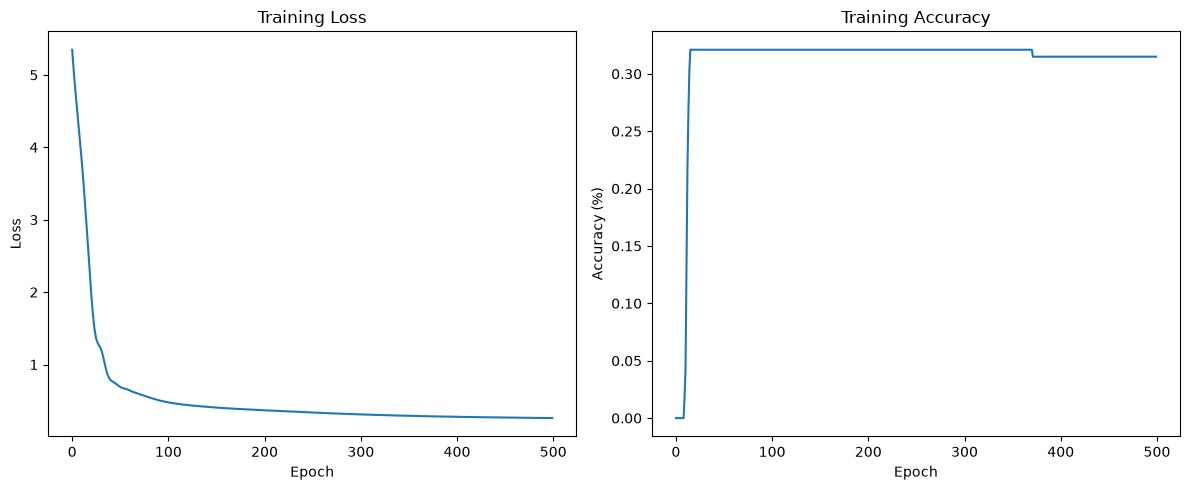

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(loss_history)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()

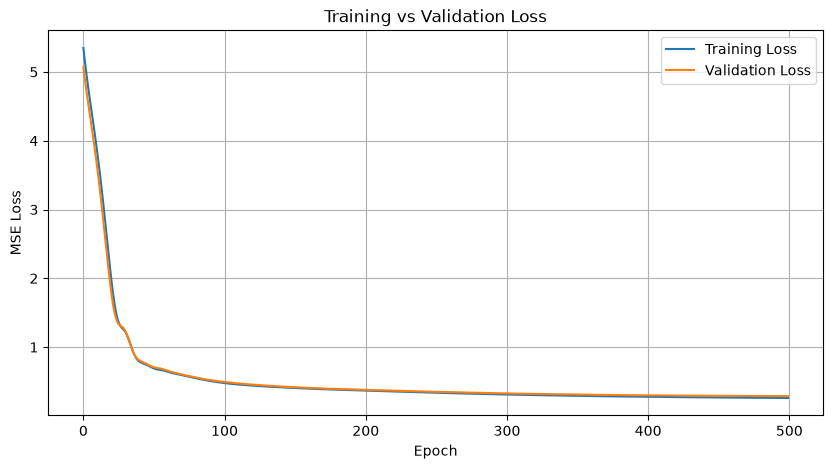

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(loss_history, label="Training Loss")
plt.plot(val_loss_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Model Evaluation
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error

model.eval()
with torch.no_grad():
    predictions = model(
        X_test_tensor
    ).cpu().numpy()

mse = mean_squared_error(
    y_test,
    predictions
)

r2 = r2_score(
    y_test,
    predictions
)
mae = mean_absolute_error(y_test, predictions)

print("MSE:", mse)
print("R2:", r2)
print("MAE:", mae)

MSE: 0.2870419605242272
R2: 0.7809523856364644
MAE: 0.36909485864326474


In [16]:
#Predict New House Price
new_house = [[
    5.0,    # MedInc
    25.0,   # HouseAge
    6.5,    # AveRooms
    1.1,    # AveBedrms
    1000,   # Population
    3.0,    # AveOccup
    34.0,   # Latitude
    -118.0  # Longitude
]]

In [17]:
new_house_scaled = scaler.transform(
    new_house
)
device = next(
    model.parameters()
).device


new_tensor = torch.tensor(
    new_house_scaled,
    dtype=torch.float32
).to(device)

model.eval()

with torch.no_grad():
    price = model(
        new_tensor
    )

print(
    "Predicted House Price:",
     price.item() * 100000
)

Predicted House Price: 256683.87413024902


e:\aiml\pyvenvlib\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


### Summary:

This model is a 4-layer fully connected Deep Neural Network (MLP) with architecture 8 → 64 → 128 → 64 → 1, trained using Adam optimizer and MSE loss to predict California house prices from 8 housing features.
